# Complete the Look: Learned vs. Similarity-based Recommendation on Pinterest

**Question.** A user is looking at an outfit photo (a *scene*). Which *product* (shoes, bag, ...) goes with it?
New photos have no interaction history, so this is a **cold-start recommendation** problem that has to be solved from image content.

**What we compare: two recommendation methods on the same image features.**

| | Method A: Visual BPR | Method B: Hybrid kNN |
|---|---|---|
| Type | **model-based**: learns latent factors | **memory-based**: nearest-neighbour similarity |
| How it scores | dot product in a learned compatibility space | similarity-weighted vote: products used by similar outfits (CF) + products that look like them (content) |
| From class | BPR, latent factor models, VBPR | similarity-based / item-to-item recommendation |
| Training | BPR with sampled negatives | none (only $K$ and $\lambda$ are tuned) |

Both methods use the same frozen image features (a CNN and a Transformer encoder), the same split and the same evaluation.
Method A is implemented below. Method B is a template for the teammate.

**Outline:** 1. Task · 2. Data · 3. Baselines · 4. Image features · 5. Method A · 6. Method B · 7. Results · 8. Error analysis · 9. Related work

## 1. Predictive task

* **Input:** a scene photo with the target product **greyed out** (otherwise the model could just "see" the answer), and the product's category.
* **Output:** a ranking of 100 candidate products of that category: 1 true product + 99 random negatives.
* **Metrics:** **AUC** (quality of the whole ranking), **Hit@10** (is the true product in the top 10?), and **NDCG@10** (the higher it is ranked, the better).
* **Validity:** we split by scene, so every test photo is new. The negatives come from the same category, so the model has to judge *style*, not just *category*.

In [1]:
import json, os, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams['figure.dpi'] = 110

## 2. Data

**Pinterest Fashion Compatibility** (Kang et al., *Complete the Look*, CVPR 2019; https://github.com/kang205/STL-Dataset).
Each record says that a product appears in a scene photo, and gives its bounding box. The labels come from Pinterest's "Shop the Look" annotations.
`prepare_data.py` downloads the images and turns each one into a feature vector with the image encoders; this notebook only loads those vectors.

In [2]:
pairs = pd.DataFrame([json.loads(l) for l in open('data/fashion.json')])
cat_full = json.load(open('data/fashion-cat.json'))
pairs['category'] = pairs['product'].map(lambda p: cat_full[p].split('|')[-1])

n_s, n_p = pairs.scene.nunique(), pairs['product'].nunique()
pd.Series({'pairs': len(pairs), 'scenes': n_s, 'products': n_p, 'categories': pairs.category.nunique(),
           'products per scene': round(len(pairs) / n_s, 2),
           'products that appear in only 1 scene': f"{(pairs['product'].value_counts() == 1).mean():.0%}"}).to_frame('value')

,value
pairs,72198
scenes,29438
products,38111
categories,10
products per scene,2.45
products that appear in only 1 scene,70%


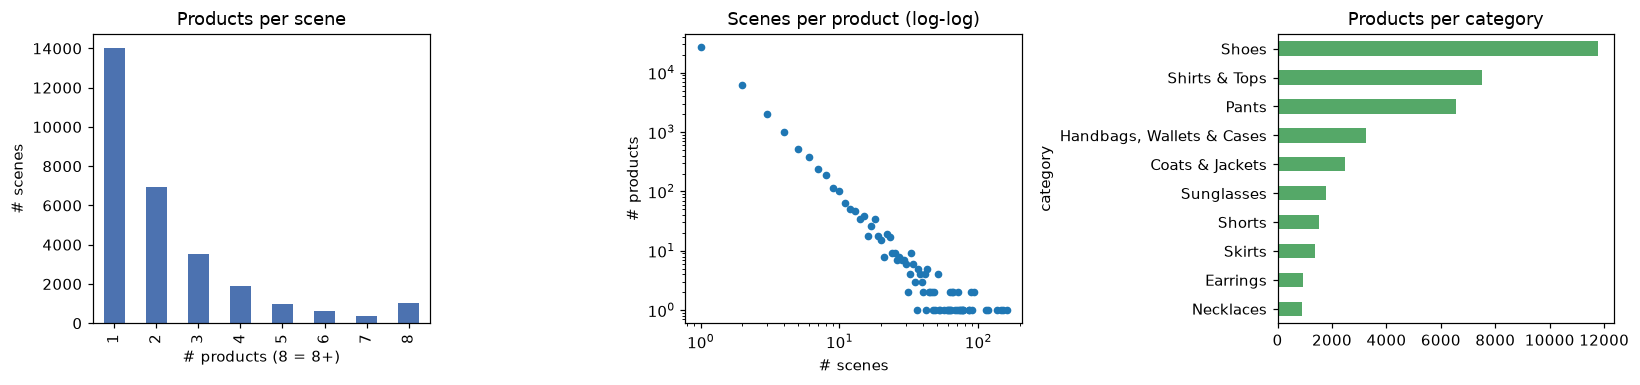

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pairs.groupby('scene').size().clip(upper=8).value_counts().sort_index().plot.bar(ax=ax[0], color='#4C72B0')
ax[0].set(title='Products per scene', xlabel='# products (8 = 8+)', ylabel='# scenes')
vc = pairs['product'].value_counts().value_counts().sort_index()
ax[1].loglog(vc.index, vc.values, 'o', ms=4); ax[1].set(title='Scenes per product (log-log)', xlabel='# scenes', ylabel='# products')
pairs.drop_duplicates('product').category.value_counts().plot.barh(ax=ax[2], color='#55A868')
ax[2].set(title='Products per category'); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

**Takeaway:** the data is extremely sparse, and 70% of products appear in only one scene. Collaborative filtering by ID has almost nothing to learn from, so we need the **images**.

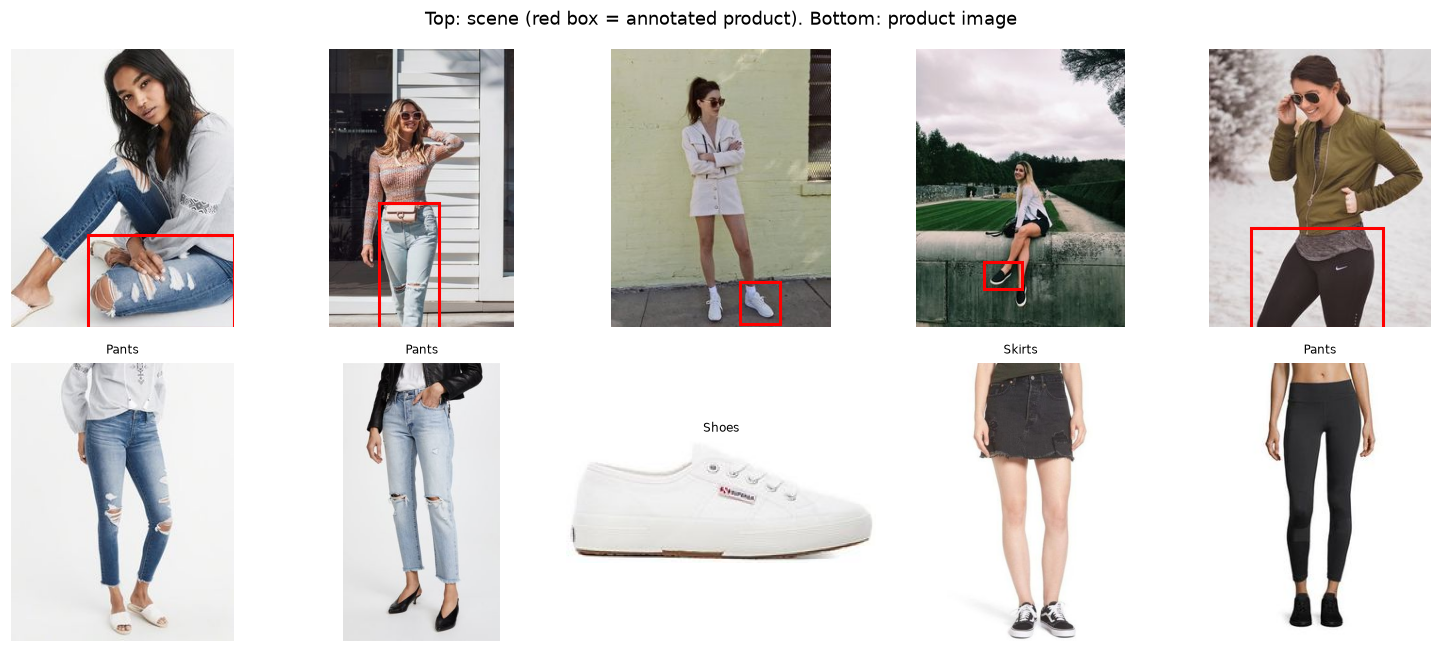

In [4]:
def img(sig):
    p = f'data/images/{sig}.jpg'
    return Image.open(p).convert('RGB') if os.path.exists(p) else Image.new('RGB', (236, 236), 'white')

fig, ax = plt.subplots(2, 5, figsize=(14, 6))
for i, (_, r) in enumerate(pairs.sample(5, random_state=1).iterrows()):
    im = img(r.scene); w, h = im.size; l, t, rr, b = r.bbox
    ax[0, i].imshow(im); ax[0, i].add_patch(plt.Rectangle((l*w, t*h), (rr-l)*w, (b-t)*h, fill=False, ec='red', lw=2))
    ax[1, i].imshow(img(r['product'])); ax[1, i].set_title(r.category, fontsize=8)
    ax[0, i].axis('off'); ax[1, i].axis('off')
plt.suptitle('Top: scene (red box = annotated product). Bottom: product image'); plt.tight_layout(); plt.show()

### Split, negatives, and the evaluation function
Scenes are split 80/10/10 into train / valid / test. Each held-out pair gets 99 fixed negatives from the same category, so every model is scored on exactly the same candidates.

In [5]:
idx = json.load(open('data/feat_index.json'))
pid = {p: i for i, p in enumerate(idx['products'])}
pairs['p'], pairs['row'] = pairs['product'].map(pid), np.arange(len(pairs))

rng = np.random.default_rng(SEED)
scenes = pairs.scene.unique().tolist(); rng.shuffle(scenes); n = len(scenes)
split = {s: 'train' if i < .8 * n else 'valid' if i < .9 * n else 'test' for i, s in enumerate(scenes)}
pairs['split'] = pairs.scene.map(split)
train, valid, test = (pairs[pairs.split == k].reset_index(drop=True) for k in ['train', 'valid', 'test'])

prod_cat = pairs.drop_duplicates('p').set_index('p').category
cat_products = {c: g.index.values for c, g in prod_cat.groupby(prod_cat)}
train_products = set(train.p)
train_cat_products = {c: np.array([p for p in v if p in train_products]) for c, v in cat_products.items()}
scene_pos = pairs.groupby('scene').p.apply(set).to_dict()

def sample_negatives(df, seed, k=99):
    r = np.random.default_rng(seed)
    return np.array([[x for x in r.choice(cat_products[c], 3 * k) if x not in scene_pos[s]][:k]
                     for s, c in zip(df.scene, df.category)])
NEG = {'valid': sample_negatives(valid, 1), 'test': sample_negatives(test, 2)}
print({k: len(v) for k, v in [('train', train), ('valid', valid), ('test', test)]},
      f"| test products also seen in train: {test.p.isin(train_products).mean():.0%}")

def evaluate(score_fn, df, neg, K=10):
    cand = np.concatenate([df.p.values[:, None], neg], 1)           # column 0 = true product
    s = np.asarray(score_fn(df, cand), dtype=float)
    rank = (s[:, 1:] > s[:, :1]).sum(1) + 0.5 * (s[:, 1:] == s[:, :1]).sum(1)  # 0 = top
    return {'AUC': 1 - rank.mean() / neg.shape[1], 'Hit@10': (rank < K).mean(),
            'NDCG@10': np.where(rank < K, 1 / np.log2(rank + 2), 0).mean(), 'rank': rank}

results = {}
def report(name, fn):
    r = evaluate(fn, test, NEG['test'])
    results[name] = {k: r[k] for k in ['AUC', 'Hit@10', 'NDCG@10']}
    print(f"{name:28s} AUC {r['AUC']:.4f}  Hit@10 {r['Hit@10']:.4f}  NDCG@10 {r['NDCG@10']:.4f}")
    return r['rank']

{'train': 57600, 'valid': 7097, 'test': 7501} | test products also seen in train: 59%


## 3. Baselines (from class)

* **Random:** lower bound (AUC 0.5, Hit@10 about 0.10).
* **Popularity:** rank products by how many training scenes they appear in.
* **BPR-MF:** $f(s,p)=\beta_p+\gamma_s^\top\gamma_p$, trained with BPR. Test scenes are new, so they have no $\gamma_s$ and only the item bias $\beta_p$ is left. This is the **cold-start problem**.

In [6]:
def train_bpr(model, batch_scores, epochs=15, lr=1e-3, wd=1e-5, bs=1024):
    # generic BPR loop: maximise log sigma(score(pos) - score(neg)), with a same-category negative
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    r = np.random.default_rng(SEED)
    for ep in range(epochs):
        model.train()
        for i in range(0, len(train), bs):
            b = train.iloc[r.permutation(len(train))[:bs]]
            neg = np.array([r.choice(train_cat_products[prod_cat[p]]) for p in b.p])
            pos_s, neg_s = batch_scores(model, b, neg)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

class BPRMF(nn.Module):
    def __init__(self, n_s, n_p, k=32):
        super().__init__()
        self.gs, self.gp, self.bp = nn.Embedding(n_s, k), nn.Embedding(n_p, k), nn.Embedding(n_p, 1)
        nn.init.normal_(self.gs.weight, std=.01); nn.init.normal_(self.gp.weight, std=.01); nn.init.zeros_(self.bp.weight)
    def forward(self, s, p):
        return self.bp(p).squeeze(-1) + (self.gs(s) * self.gp(p)).sum(-1)

sid = {s: i for i, s in enumerate(pairs.scene.unique())}
T = torch.tensor
mf = train_bpr(BPRMF(len(sid), len(pid)), lambda m, b, neg: (
    m(T(b.scene.map(sid).values), T(b.p.values)), m(T(b.scene.map(sid).values), T(neg))), epochs=20, lr=5e-3)
item_bias = mf.bp.weight.detach().squeeze(-1).numpy()
pop = np.bincount(train.p, minlength=len(pid)).astype(float)
noise = np.random.default_rng(0)

report('Random', lambda df, c: noise.random(c.shape))
report('Popularity', lambda df, c: pop[c] + 1e-3 * noise.random(c.shape))
report('BPR-MF', lambda df, c: item_bias[c]);

Random                       AUC 0.4996  Hit@10 0.1075  NDCG@10 0.0476
Popularity                   AUC 0.4959  Hit@10 0.3108  NDCG@10 0.2049
BPR-MF                       AUC 0.7054  Hit@10 0.3092  NDCG@10 0.2003


## 4. Shared input: image features

Both methods work on the **same fixed image features**. A pretrained image encoder turns every image into a 512-d vector $\phi(\cdot)$.
The scene is encoded **with the target product greyed out**, and each product is encoded on its own. The encoders are frozen (we do not train them).
We try two encoders, so we can check whether our conclusions depend on the features:

* **CNN, ResNet-101** (CLIP, OpenAI): convolution filters. Strong on local texture, colour and pattern.
* **Transformer, ViT-B/32** (CLIP, LAION-2B): 32×32 patches that attend to each other. Strong on global layout.

In [7]:
FEATS = {tag: (np.load(f'data/feat_{tag}_product.npy').astype(np.float32),       # [n_products, 512]
               np.load(f'data/feat_{tag}_scene_masked.npy').astype(np.float32))  # [n_pairs, 512]
         for tag in ['cnn', 'vit']}
pd.DataFrame({t: json.load(open(f'data/encoder_{t}.json')) for t in FEATS}).T[['arch', 'params_M', 'embed_dim', 'images_per_sec']]

,arch,params_M,embed_dim,images_per_sec
cnn,RN101,56.3,512,39.4
vit,ViT-B-32,87.8,512,145.4


## 5. Method A: Visual BPR (model-based)

We learn a **compatibility space** with BPR, as in VBPR (He & McAuley, 2016), the visual extension of BPR from class:

$$f(s,p) \;=\; \big\langle\, A\,\phi(s) + e_{c},\;\; B\,\phi(p) \,\big\rangle \;+\; w^\top\phi(p)$$

* $A, B$: project scenes and products into a shared space where **"goes well together" means a high dot product**. Jeans and a jacket do not have to look alike to be compatible.
* $e_c$: category embedding, so the query becomes "which **shoes** go with this outfit?".
* $w^\top\phi(p)$: visual bias, i.e. how generally appealing a product looks. It works for brand-new products.

It is trained with BPR and same-category negatives. We train it once per feature set and keep the one with the better **validation** AUC.

In [8]:
cats = sorted(cat_products); cat_id = {c: i for i, c in enumerate(cats)}

class VisualBPR(nn.Module):
    def __init__(self, D, d=256):
        super().__init__()
        self.A, self.B = nn.Linear(D, d, bias=False), nn.Linear(D, d, bias=False)
        self.cat = nn.Embedding(len(cats), d); nn.init.zeros_(self.cat.weight)
        self.w = nn.Linear(D, 1, bias=False)
        self.drop = nn.Dropout(0.2)
    def forward(self, f_scene, c, f_prod):              # f_prod: [n, D] or [n, k, D]
        q = self.A(self.drop(f_scene)) + self.cat(c)
        v = self.B(self.drop(f_prod))
        if f_prod.dim() == 3: q = q[:, None, :]
        return (q * v).sum(-1) + self.w(f_prod).squeeze(-1)

def run_visual_bpr(tag):
    P, S = FEATS[tag]
    inputs = lambda b: (T(S[b.row.values]), T(b.category.map(cat_id).values))
    torch.manual_seed(SEED)
    model = train_bpr(VisualBPR(P.shape[1]), lambda m, b, neg: (m(*inputs(b), T(P[b.p.values])),
                                                                 m(*inputs(b), T(P[neg]))))
    def score(df, cand):
        with torch.no_grad(): return model(*inputs(df), T(P[cand])).numpy()
    return score

method_A = {}
for tag, name in [('cnn', 'CNN'), ('vit', 'ViT')]:
    score = run_visual_bpr(tag)
    method_A[tag] = dict(score=score, valid_auc=evaluate(score, valid, NEG['valid'])['AUC'],
                         rank=report(f'A: Visual BPR ({name})', score))
best_A = max(method_A, key=lambda t: method_A[t]['valid_auc'])
score_A, rank_A = method_A[best_A]['score'], method_A[best_A]['rank']
print('features chosen on validation:', best_A)

A: Visual BPR (CNN)          AUC 0.7396  Hit@10 0.3473  NDCG@10 0.1829


A: Visual BPR (ViT)          AUC 0.7791  Hit@10 0.4202  NDCG@10 0.2322
features chosen on validation: vit


## 6. Method B: Hybrid kNN (similarity-based), *template for the teammate*

**Idea (neighbourhood recommendation, as in item-to-item CF from class):** outfits that look alike are completed by the same, or similar-looking, products.

For a query scene $s$ asking for category $c$:
1. Find the $K$ **training** scenes most similar to $s$, by cosine similarity of masked-scene features, among training pairs of category $c$.
2. Each neighbour $n$ comes with the product $p_n$ that actually completed it.
3. Score each candidate with a **collaborative** term (did a similar outfit use exactly this product?) and a **content** term (does it look like the products similar outfits used?):

$$f(s,p) = \sum_{n \in \mathcal{N}_K(s)} \cos(\phi(s), \phi(s_n)) \cdot \Big[\ \lambda\,\mathbb{1}(p = p_n) \;+\; (1-\lambda)\,\cos(\phi(p), \phi(p_n))\ \Big]$$

* $\lambda = 0$: pure visual kNN (content only)
* $\lambda = 1$: pure neighbourhood CF (only products seen in training can score)
* $0 < \lambda < 1$: hybrid. This mirrors Method A, which also combines product ID factors with visual factors, so the comparison is **learned (A) vs. neighbourhood (B)** using the same signals.

There is nothing to train: tune $K$ and $\lambda$ on the **validation** split. Report $\lambda=0$, $\lambda=1$ and the best $\lambda$, on `FEATS['vit']` (and optionally `FEATS['cnn']`).

**To finish:** implement `hybrid_knn` so that it returns `score_B(df, cand)`, a `[len(df), 100]` score matrix, then set `rank_B = report('B: Hybrid kNN (...)', score_B)`.
The results table, the category breakdown and the error analysis below pick up Method B automatically.

In [9]:
# TODO (teammate): Method B - Hybrid kNN
def hybrid_knn(tag, K=50, lam=0.5):
    P, S = FEATS[tag]
    # 1. training queries S[train.row] with their products train.p, grouped by category
    # 2. for each query in df: cosine similarity to the training queries of the same category, keep the top K
    # 3. for each candidate p in cand, sum over neighbours n:
    #        sim(query, n) * ( lam * (p == p_n) + (1 - lam) * cos(P[p], P[p_n]) )
    raise NotImplementedError

# tune K and lam on (valid, NEG['valid']) with evaluate(), then e.g.:
# score_B = hybrid_knn('vit', K=..., lam=...); rank_B = report('B: Hybrid kNN (ViT)', score_B)
score_B, rank_B = None, None

## 7. Results

**Why these metrics?** AUC scores the whole ranking. Hit@10 and NDCG@10 score what a user actually sees, which is the top of a "Complete the Look" carousel.

,AUC,Hit@10,NDCG@10
Random,0.500,0.107,0.048
Popularity,0.496,0.311,0.205
BPR-MF,0.705,0.309,0.200
A: Visual BPR (CNN),0.740,0.347,0.183
A: Visual BPR (ViT),0.779,0.420,0.232


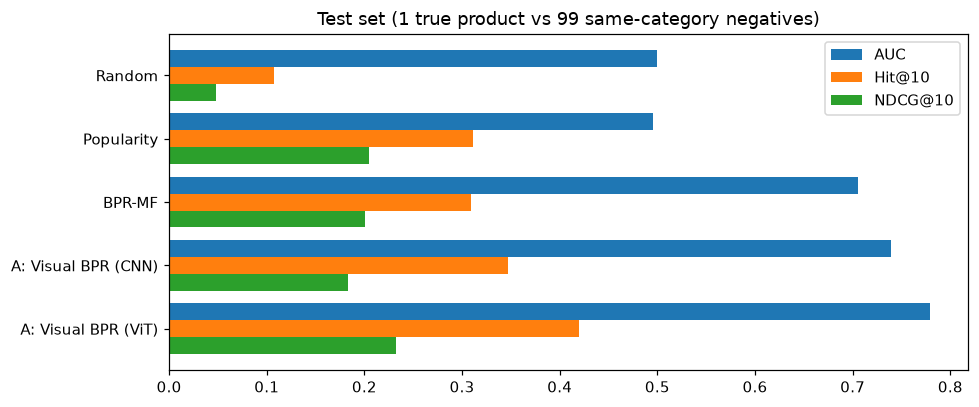

In [10]:
res = pd.DataFrame(results).T
display(res.style.format('{:.3f}').highlight_max(axis=0, color='#c6efce'))
ax = res.plot.barh(figsize=(9, 3.8), width=.8); ax.invert_yaxis(); ax.set_title('Test set (1 true product vs 99 same-category negatives)')
plt.tight_layout(); plt.show()

### Where does each method win? (Hit@10 by category)

In [11]:
ranks = {'Hit@10 A (Visual BPR)': rank_A}
if rank_B is not None: ranks['Hit@10 B (Hybrid kNN)'] = rank_B
by = test.assign(**{k: r < 10 for k, r in ranks.items()},
                 product=np.where(test.p.isin(train_products), 'product seen in train', 'unseen product'))
pd.concat([by.groupby('category')[list(ranks)].mean().assign(n=by.category.value_counts()),
           by.groupby('product')[list(ranks)].mean().assign(n=by['product'].value_counts())]).round(3)

,Hit@10 A (Visual BPR),n
Coats & Jackets,0.424,455
Earrings,0.299,147
"Handbags, Wallets & Cases",0.347,649
Necklaces,0.200,100
Pants,0.434,1505
Shirts & Tops,0.397,1217
Shoes,0.484,2545
Shorts,0.305,308
Skirts,0.376,157
Sunglasses,0.354,418


## 8. Error analysis

The helper below shows a query scene (product greyed out) and a method's top-5 recommendations. The true product is outlined in green.

In [12]:
def show_recs(score_fn, rows, title, top=5):
    df = test.iloc[rows]; cand = np.concatenate([df.p.values[:, None], NEG['test'][rows]], 1)
    sc = score_fn(df, cand)
    fig, ax = plt.subplots(len(rows), top + 1, figsize=(2.1 * (top + 1), 2.3 * len(rows)))
    for i in range(len(rows)):
        r = df.iloc[i]; im = img(r.scene); w, h = im.size; l, t, rr, b = r.bbox
        ax[i, 0].imshow(im); ax[i, 0].add_patch(plt.Rectangle((l*w, t*h), (rr-l)*w, (b-t)*h, color='grey'))
        ax[i, 0].set_title(f'query: {r.category}', fontsize=8)
        for j, k in enumerate(np.argsort(-sc[i])[:top]):
            ax[i, j + 1].imshow(img(idx['products'][cand[i, k]]))
            if k == 0:
                for s in ax[i, j + 1].spines.values(): s.set(color='green', lw=4)
        for a in ax[i]: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(title); plt.tight_layout(); plt.show()

pick = lambda mask, n=3: np.random.default_rng(4).choice(np.where(mask)[0], n, replace=False)

### 8a. Method A (Visual BPR): where it fails
Test scenes where Visual BPR ranks the true product **outside its top 10**. Once Method B exists, `pick((rank_A >= 10) & (rank_B < 3))` shows the cases hybrid kNN gets right instead.

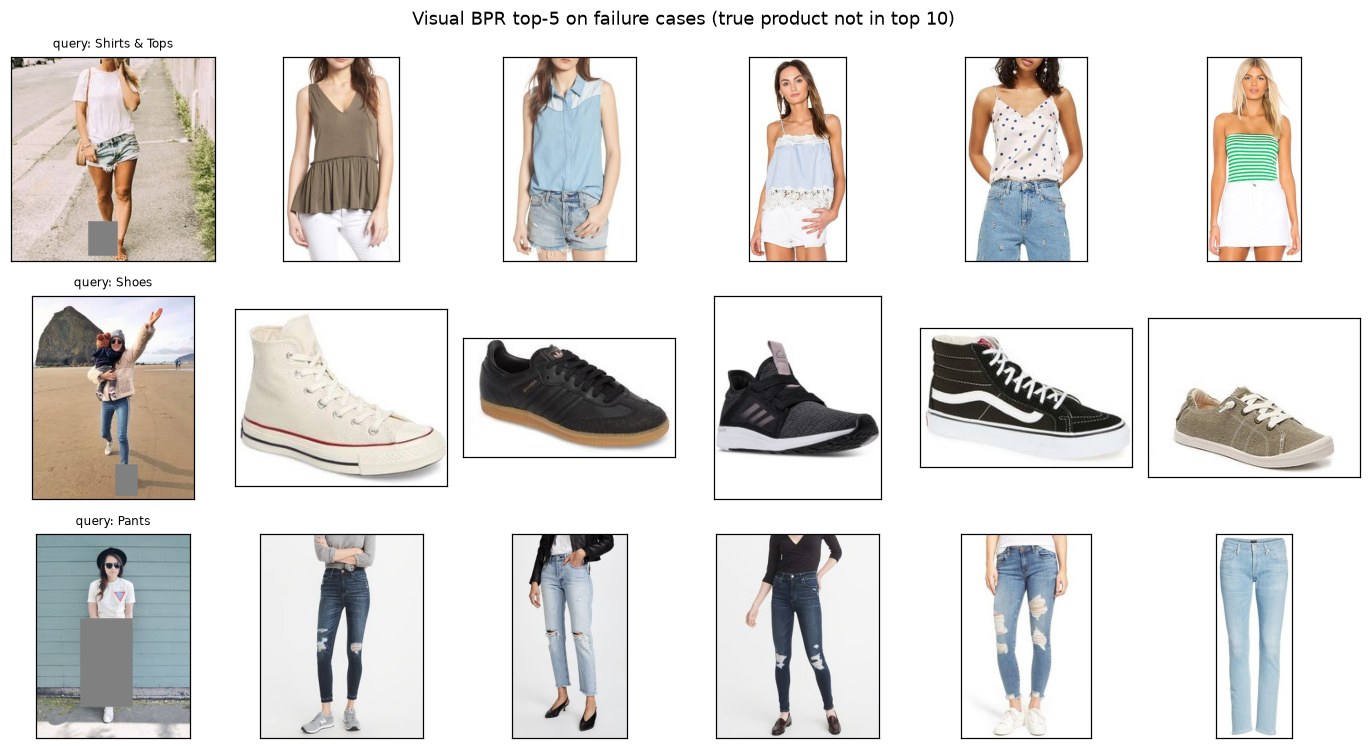

In [13]:
show_recs(score_A, pick(rank_A >= 10), 'Visual BPR top-5 on failure cases (true product not in top 10)')

*Observations (Method A):* to be filled in.

### 8b. Method B (Hybrid kNN): *template for the teammate*
Use `show_recs(score_B, pick(rank_B >= 10), ...)` for hybrid kNN failure cases, and `pick((rank_B >= 10) & (rank_A < 3))` for the cases where Visual BPR wins.

In [14]:
# TODO (teammate): error analysis for Method B
if score_B is not None:
    show_recs(score_B, pick(rank_B >= 10), 'Hybrid kNN top-5 on failure cases')

## 9. Related work

* **Complete the Look** (Kang et al., CVPR 2019) introduced this dataset. It combines global and *local* (region-level attention) compatibility on ResNet features, and evaluates with AUC and Hit@K against same-category negatives.
* **Model-based:** BPR (Rendle et al., UAI 2009) and VBPR (He & McAuley, AAAI 2016). Method A follows this line.
* **Memory-based:** item-based collaborative filtering (Sarwar et al., WWW 2001; Linden et al., Amazon, 2003). Method B follows this line, with visual similarity in place of co-purchase similarity.
* **Image encoders:** ResNet (He et al., CVPR 2016), ViT (Dosovitskiy et al., ICLR 2021), and CLIP pre-training (Radford et al., ICML 2021).
* **Industry:** Pinterest's PinSage (Ying et al., KDD 2018) combines visual and text features with the pin–board graph for web-scale recommendation.

---
*Save the headline numbers (used to build the slides).*

In [15]:
summary = {'results': results, 'best_A_features': best_A,
           'hit10_by_category': by.groupby('category')['Hit@10 A (Visual BPR)'].mean().round(4).to_dict(),
           'encoders': {t: json.load(open(f'data/encoder_{t}.json')) for t in ['cnn', 'vit']}}
json.dump(summary, open('results_summary.json', 'w'), indent=1)